# UNet Cityscapes — Training on Colab

**Workflow:**
1. GPU check
2. Mount Drive + clone repo
3. Copy data from Drive → /content/ (fast SSD)
4. Install dependencies
5. Configure & train
6. Evaluate & visualize

> **Before running:** upload `cityscapes_preprocessed.zip` to your Google Drive root.

## 1 — GPU Check

In [ ]:
import torch

assert torch.cuda.is_available(), "No GPU found. Change runtime to GPU in Runtime > Change runtime type."

gpu_name = torch.cuda.get_device_name(0)
vram_gb = torch.cuda.get_device_properties(0).total_memory / 1e9
print(f"GPU : {gpu_name}")
print(f"VRAM: {vram_gb:.1f} GB")

# EfficientNet-B4 @ 1024x512 uses ~4x more VRAM than ResNet34 @ 512x256
BATCH_SIZE = 4 if vram_gb >= 30 else 2
print(f"Batch size: {BATCH_SIZE}")

GPU : NVIDIA L4
VRAM: 23.7 GB
Batch size: 2


## 2 — Mount Drive & Clone Repo

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# TODO: replace with your GitHub repo URL
REPO_URL = "https://github.com/JulesV19/road-segmentation.git"

import subprocess
result = subprocess.run(
    ["git", "clone", REPO_URL, "/content/road-segmentation"],
    capture_output=True, text=True
)
print(result.stdout or result.stderr)

%cd /content/road-segmentation

Mounted at /content/drive
Cloning into '/content/road-segmentation'...

/content/road-segmentation


## 3 — Install Dependencies

In [ ]:
!pip install -r requirements.txt -q
print("Dependencies installed.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 6.6 MB/s eta 0:00:00
Dependencies installed.


## 4 — Copy Data from Drive → /content/

> **Why?** Reading directly from Drive during training is ~10× slower than reading from /content/ SSD.
> This one-time copy takes ~30–60s and pays off across every epoch.

In [ ]:
import time

# Path to the zip on Drive — adjust if you put it in a subfolder
# Re-run preprocess.py locally with --width 1024 --height 512 before uploading:
#   python scripts/preprocess.py --data_root /path/to/cityscapes \
#       --output_dir /path/to/preprocessed --width 1024 --height 512
# Then zip and upload: zip -r cityscapes_preprocessed_1024.zip preprocessed/
DRIVE_ZIP = "/content/drive/MyDrive/cityscapes_preprocessed_1024.zip"

t0 = time.time()
!unzip -q "{DRIVE_ZIP}" -d /content/
elapsed = time.time() - t0
print(f"Data ready in {elapsed:.1f}s")

# Quick sanity checks
!echo "Train samples:" && wc -l /content/preprocessed/train.csv
!echo "Val samples  :" && wc -l /content/preprocessed/val.csv
!ls /content/preprocessed/

Data ready in 63.6s
Train samples:
2976 /content/preprocessed/train.csv
Val samples  :
501 /content/preprocessed/val.csv
images	masks  train.csv  val.csv


## 5 — Configuration

In [ ]:
import os
import yaml

with open("configs/config.yaml") as f:
    cfg = yaml.safe_load(f)

# Override paths for Colab
cfg["data"]["root"] = "/content/preprocessed"
cfg["training"]["batch_size"] = BATCH_SIZE
cfg["checkpointing"]["dir"] = "/content/drive/MyDrive/road_seg_checkpoints"

os.makedirs(cfg["checkpointing"]["dir"], exist_ok=True)

print("Config loaded:")
print(f"  data root      : {cfg['data']['root']}")
print(f"  batch size     : {cfg['training']['batch_size']}")
print(f"  epochs         : {cfg['training']['epochs']}")
print(f"  lr             : {cfg['training']['lr']}")
print(f"  mixed precision: {cfg['training']['mixed_precision']}")
print(f"  checkpoint dir : {cfg['checkpointing']['dir']}")

Config loaded:
  data root      : /content/preprocessed
  batch size     : 2
  epochs         : 50
  lr             : 0.0003
  mixed precision: True
  checkpoint dir : /content/drive/MyDrive/road_seg_checkpoints


## 6 — (Optional) Resume from Checkpoint

In [ ]:
import glob

RESUME = False   # Set True to resume from last checkpoint

resume_path = None
if RESUME:
    last = "/content/drive/MyDrive/road_seg_checkpoints/last.pth"
    if os.path.exists(last):
        resume_path = last
        print(f"Will resume from: {resume_path}")
    else:
        print("No checkpoint found, starting from scratch.")

## 7 — Train

In [ ]:
import sys
sys.path.insert(0, "/content/road-segmentation")

from src.train import train

model = train(cfg, resume_from=resume_path)

Device: cuda


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:122: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


config.json:   0%|          | 0.00/106 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/77.9M [00:00<?, ?B/s]


Epoch 1/50 — best mIoU so far: 0.0000


...

  train_loss=0.0491  val_loss=0.1236  val_mIoU=0.8415
  *** New best mIoU: 0.8415 — checkpoint saved ***

Epoch 47/50 — best mIoU so far: 0.8415


  train_loss=0.0490  val_loss=0.1236  val_mIoU=0.8418
  *** New best mIoU: 0.8418 — checkpoint saved ***

Epoch 48/50 — best mIoU so far: 0.8418


  train_loss=0.0488  val_loss=0.1234  val_mIoU=0.8414

Epoch 49/50 — best mIoU so far: 0.8418


  train_loss=0.0489  val_loss=0.1243  val_mIoU=0.8419
  *** New best mIoU: 0.8419 — checkpoint saved ***

Epoch 50/50 — best mIoU so far: 0.8419


  train_loss=0.0488  val_loss=0.1234  val_mIoU=0.8411

Training complete. Best val mIoU: 0.8419


## 8 — Evaluate & Visualize on Validation Set

In [ ]:
import torch
import matplotlib.pyplot as plt

from src.dataset import build_loaders
from src.metrics import compute_miou, CLASS_NAMES
from src.utils import visualize_predictions, load_checkpoint
from src.model import build_model

device = "cuda"

# Load best checkpoint
import glob
best_ckpts = sorted(glob.glob("/content/drive/MyDrive/road_seg_checkpoints/best_*.pth"))
if best_ckpts:
    best_path = best_ckpts[-1]
    print(f"Loading best checkpoint: {best_path}")
    model = build_model(cfg).to(device)
    epoch, best_miou = load_checkpoint(best_path, model, device=device)
    print(f"Best val mIoU: {best_miou:.4f} (epoch {epoch+1})")
else:
    print("Using model from training session.")
    model = model.to(device)

model.eval()
_, val_loader = build_loaders(cfg)

# Per-class mIoU on full val set
all_ious = []
with torch.no_grad():
    for images, masks in val_loader:
        images, masks = images.to(device), masks.to(device)
        with torch.amp.autocast("cuda"):
            logits = model(images)
        preds = logits.argmax(dim=1)
        miou, per_class = compute_miou(preds, masks, num_classes=cfg["model"]["num_classes"])
        all_ious.append(per_class)

# Average per class across batches (ignoring NaN)
import numpy as np
all_ious = np.array(all_ious, dtype=float)   # (n_batches, n_classes-1)
mean_per_class = np.nanmean(all_ious, axis=0)
mean_miou = np.nanmean(mean_per_class)

print(f"\nVal mIoU: {mean_miou:.4f}")
print("Per-class IoU:")
for name, iou in zip(CLASS_NAMES[1:], mean_per_class):
    print(f"  {name:<15}: {iou:.4f}")

Loading best checkpoint: /content/drive/MyDrive/road_seg_checkpoints/best_epoch049_miou0.8419.pth
Best val mIoU: 0.8418 (epoch 49)

Val mIoU: 0.8418
Per-class IoU:
  flat           : 0.9667
  construction   : 0.9001
  object         : 0.6661
  nature         : 0.8938
  sky            : 0.8775
  human          : 0.6957
  vehicle        : 0.8926


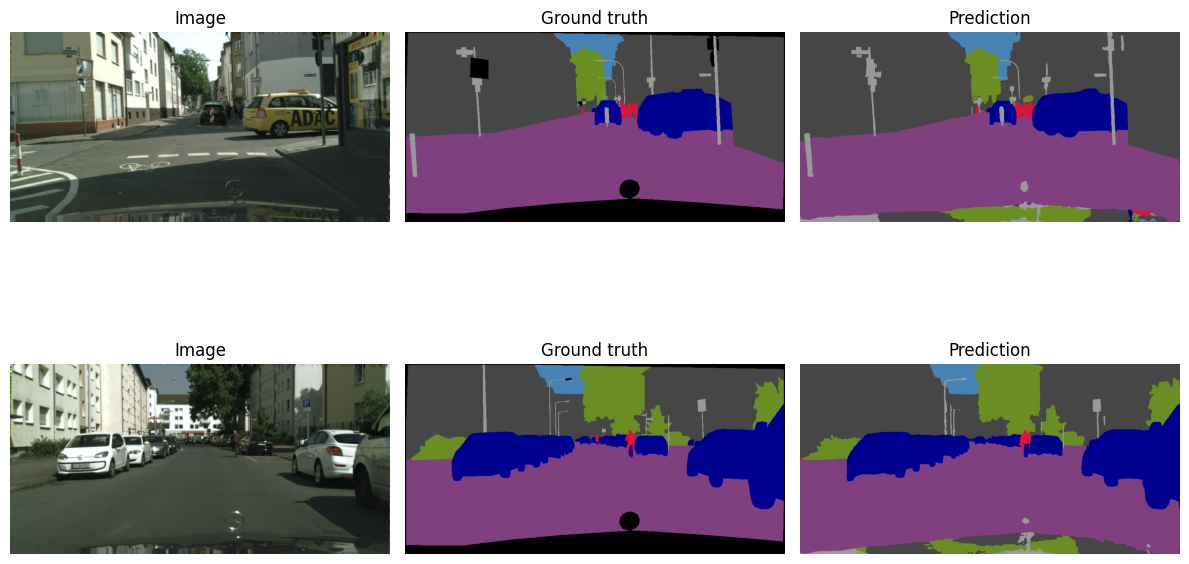

In [ ]:
# Visual check — first batch of val set
images, masks = next(iter(val_loader))
images, masks = images.to(device), masks.to(device)
with torch.no_grad(), torch.amp.autocast("cuda"):
    logits = model(images)
preds = logits.argmax(dim=1)

fig = visualize_predictions(images, masks, preds, n=4)
plt.show()

---
## 9 — Inference on Video

Upload your video to Google Drive, then set the path below and run.

In [ ]:
from src.inference import run_video
from src.model import build_model
from src.utils import load_checkpoint
import glob, os

# --- Configure these paths ---
INPUT_VIDEO  = "/content/drive/MyDrive/your_video.mp4"   # video on Drive
OUTPUT_VIDEO = "/content/output_segmented.mp4"            # written to local SSD
ALPHA        = 0.5   # 0 = original frame only, 1 = mask only

# Load best checkpoint (reuses model from cell 8 if already loaded)
if 'model' not in dir() or model is None:
    best_ckpts = sorted(glob.glob("/content/drive/MyDrive/road_seg_checkpoints/best_*.pth"))
    assert best_ckpts, "No checkpoint found — run training first (cell 7)."
    model = build_model(cfg).to("cuda")
    load_checkpoint(best_ckpts[-1], model, device="cuda")
    model.eval()
    print(f"Loaded: {best_ckpts[-1]}")

run_video(model, INPUT_VIDEO, OUTPUT_VIDEO, cfg, alpha=ALPHA, device="cuda")

ImportError: cannot import name 'run_video' from 'src.inference' (/content/road-segmentation/src/inference.py)

In [ ]:
# Copy result to Drive and preview a few frames inline
import shutil
import cv2
import matplotlib.pyplot as plt

DRIVE_OUTPUT = "/content/drive/MyDrive/output_segmented.mp4"
shutil.copy2(OUTPUT_VIDEO, DRIVE_OUTPUT)
print(f"Saved to Drive: {DRIVE_OUTPUT}")

# Preview 6 evenly-spaced frames
cap = cv2.VideoCapture(OUTPUT_VIDEO)
total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
preview_indices = [int(total * i / 5) for i in range(6)]

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for ax, idx in zip(axes.flat, preview_indices):
    cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
    ret, frame = cap.read()
    if ret:
        ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        ax.set_title(f"Frame {idx}")
    ax.axis("off")
cap.release()
plt.tight_layout()
plt.show()